# Практическая работа: бинарная классификация сердечных заболеваний

**Цель:** создать и обучить нейронную сеть, которая по медицинским показателям пациента предсказывает целевую переменную `target`.

- `target = 1` — в наборе данных отмечено наличие заболевания;
- `target = 0` — заболевание не отмечено.

Решение основано на `example.ipynb`, но код написан заново и снабжён пояснениями. Запускайте ячейки сверху вниз.

## 1. Импорт библиотек

- `pandas` (`pd`) — загрузка и обработка таблиц;
- `numpy` (`np`) — работа с числовыми массивами;
- `matplotlib.pyplot` (`plt`) — графики обучения;
- `tensorflow.keras` (`keras`) — создание и обучение нейронной сети;
- `train_test_split` — разделение данных на обучающую и тестовую выборки.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, roc_auc_score

# Фиксируем генераторы случайных чисел, чтобы результаты были воспроизводимее.
keras.utils.set_random_seed(42)

I0000 00:00:1792989268.458777   17091 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792989268.516469   17091 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792989271.099624   17091 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## 2. Загрузка данных

Сначала пробуем прочитать `heart.csv` из текущей папки. Если файла там нет, загружаем тот же CSV из репозитория-примера. Для загрузки по ссылке требуется подключение к интернету.

In [2]:
from pathlib import Path

DATA_URL = "https://raw.githubusercontent.com/vadimgb1/heart/main/heart.csv"
local_file = Path("heart.csv")

if local_file.exists():
    df = pd.read_csv(local_file)
else:
    df = pd.read_csv(DATA_URL)

print("Размер таблицы:", df.shape)
display(df.head())

Размер таблицы: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0,fixed,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3,normal,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2,reversible,0
3,37,1,3,130,250,0,0,187,0,3.5,3,0,normal,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0,normal,0


`shape` показывает количество строк и столбцов. `head()` выводит первые строки и помогает проверить, что данные загрузились. В исходном наборе ожидается 303 строки и 14 столбцов.

In [3]:
# Проверяем типы столбцов, пропуски и распределение целевого признака.
display(df.info())
print("Пропуски по столбцам:")
display(df.isna().sum())
print("Доли классов target:")
display(df["target"].value_counts(normalize=True, dropna=False))

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    str    
 13  target    303 non-null    int64  
dtypes: float64(1), int64(12), str(1)
memory usage: 33.3 KB


None

Пропуски по столбцам:


age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Доли классов target:


target
0    0.726073
1    0.273927
Name: proportion, dtype: float64

## Наглядный анализ данных

Перед обучением посмотрим на распределение целевого признака, возраст пациентов и взаимосвязи числовых показателей. Графики строятся непосредственно из `df`, поэтому обновятся при изменении данных.

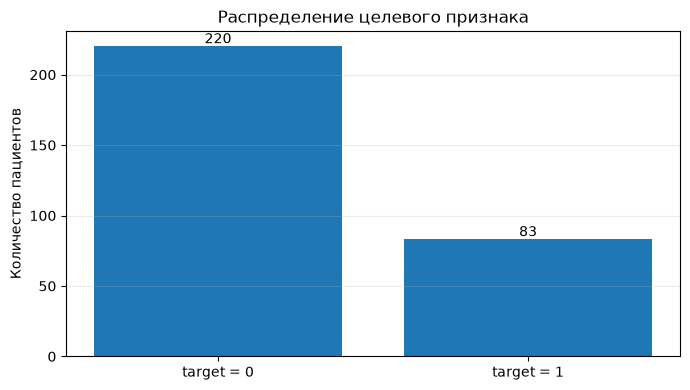

In [4]:
# 1. Сколько наблюдений относится к каждому классу target?
class_counts = df["target"].value_counts().sort_index()
labels = ["target = 0", "target = 1"]

plt.figure(figsize=(7, 4))
bars = plt.bar(labels, [class_counts.get(0, 0), class_counts.get(1, 0)])
plt.title("Распределение целевого признака")
plt.ylabel("Количество пациентов")
plt.grid(axis="y", alpha=0.25)
for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
             f"{int(bar.get_height())}", ha="center", va="bottom")
plt.tight_layout()
plt.show()


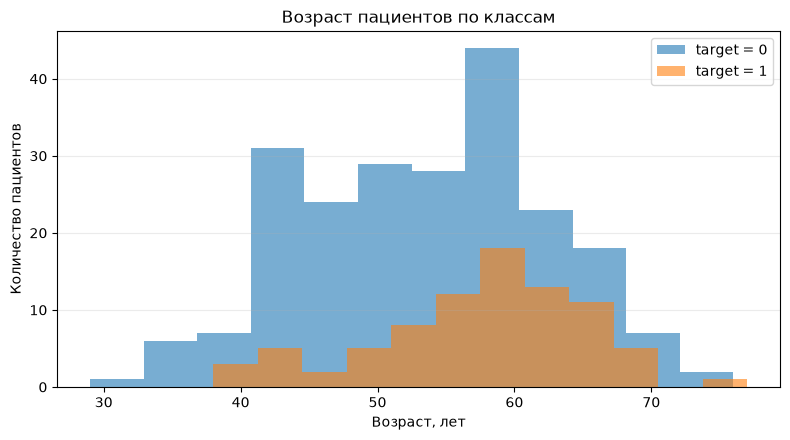

In [5]:
# 2. Распределение возраста для двух значений target
plt.figure(figsize=(8, 4.5))
for value, label in [(0, "target = 0"), (1, "target = 1")]:
    subset = df.loc[df["target"] == value, "age"]
    plt.hist(subset, bins=12, alpha=0.6, label=label)
plt.title("Возраст пациентов по классам")
plt.xlabel("Возраст, лет")
plt.ylabel("Количество пациентов")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


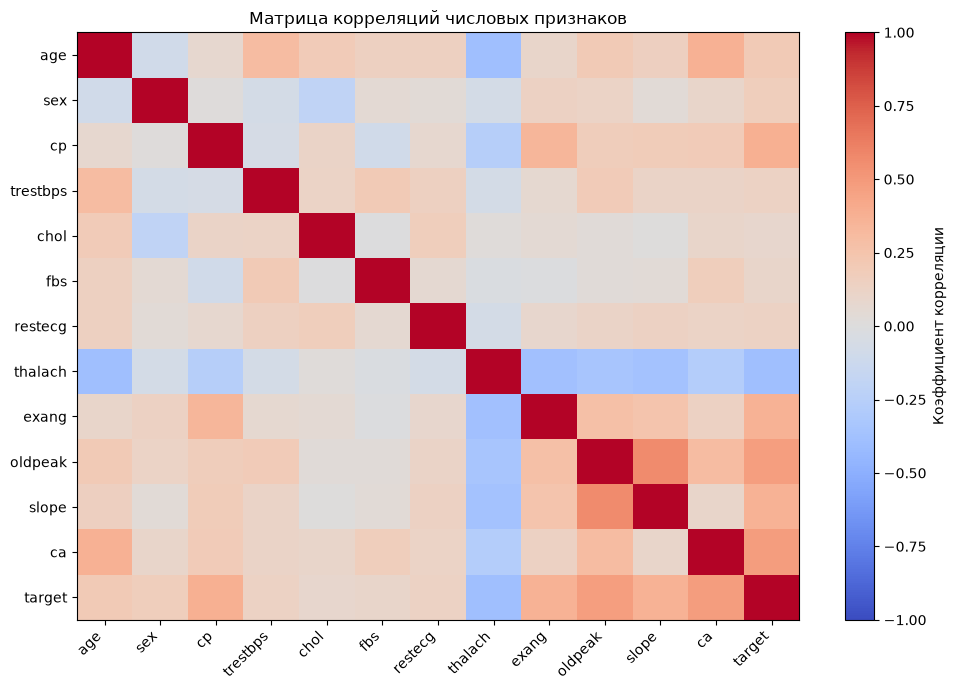

In [6]:
# 3. Корреляции числовых признаков
# Корреляция показывает линейную связь; она не доказывает причинно-следственную связь.
numeric_for_corr = df.select_dtypes(include=["number"]).columns
corr = df[numeric_for_corr].corr()

fig, ax = plt.subplots(figsize=(10, 7))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.columns)
ax.set_title("Матрица корреляций числовых признаков")
fig.colorbar(image, ax=ax, label="Коэффициент корреляции")
fig.tight_layout()
plt.show()


### Базовая модель

Наивная модель всегда предсказывает наиболее частый класс. Её точность равна доле самого частого класса. Наша нейронная сеть должна превзойти этот ориентир на тестовых данных.

In [7]:
baseline_accuracy = df["target"].value_counts(normalize=True).max()
print(f"Точность базовой модели: {baseline_accuracy:.3f} ({baseline_accuracy:.1%})")

Точность базовой модели: 0.726 (72.6%)


## 3. Предварительная обработка

Категориальные признаки преобразуем методом one-hot encoding: каждое значение категории превращается в отдельный столбец со значениями 0 и 1. Числовые признаки стандартизируем: вычитаем среднее обучающей выборки и делим на её стандартное отклонение.

Сначала отделяем `target` от признаков, а затем делим данные на обучение и тест в пропорции 80/20. Это позволяет вычислять параметры стандартизации только на обучающих данных и не подглядывать в тестовую выборку.

In [8]:
target = df["target"].astype("float32")
features = df.drop(columns=["target"])

categorical_variables = ["sex", "cp", "fbs", "restecg", "exang", "ca", "thal"]
numeric_variables = ["age", "trestbps", "chol", "thalach", "oldpeak", "slope"]

# Проверяем, что перечисленные признаки присутствуют в таблице.
missing_columns = set(categorical_variables + numeric_variables) - set(features.columns)
if missing_columns:
    raise ValueError(f"В данных отсутствуют столбцы: {sorted(missing_columns)}")

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    features, target,
    test_size=0.20,
    random_state=42,
    stratify=target
)

print("Обучающая выборка:", X_train_raw.shape)
print("Тестовая выборка:", X_test_raw.shape)

Обучающая выборка: (242, 13)
Тестовая выборка: (61, 13)


`test_size=0.20` оставляет 20% строк для итоговой проверки. `random_state=42` фиксирует разбиение. `stratify=target` сохраняет примерно такое же соотношение классов в обеих выборках.

In [10]:
# Стандартизация числовых признаков
# Преобразуем данные в float перед записью дробных значений

X_train = X_train.copy()
X_test = X_test.copy()

X_train[numeric_variables] = X_train[numeric_variables].astype("float64")
X_test[numeric_variables] = X_test[numeric_variables].astype("float64")

# Среднее и стандартное отклонение считаем только по обучающей выборке
means = X_train[numeric_variables].mean()
stds = X_train[numeric_variables].std().replace(0, 1)

# Стандартизация
X_train.loc[:, numeric_variables] = (
    X_train[numeric_variables] - means
) / stds

X_test.loc[:, numeric_variables] = (
    X_test[numeric_variables] - means
) / stds

# Подготовка данных для TensorFlow/Keras
X_train_np = X_train.to_numpy(dtype="float32")
X_test_np = X_test.to_numpy(dtype="float32")

y_train_np = y_train.to_numpy(dtype="float32")
y_test_np = y_test.to_numpy(dtype="float32")

print("Обучающая выборка:", X_train_np.shape)
print("Тестовая выборка:", X_test_np.shape)
print("Тип данных:", X_train_np.dtype)

Обучающая выборка: (242, 29)
Тестовая выборка: (61, 29)
Тип данных: float32


## 4. Создание нейронной сети

Входной слой принимает столько признаков, сколько получилось после one-hot encoding. Скрытый слой содержит 16 нейронов и функцию активации ReLU. Выходной слой содержит один нейрон с сигмоидой, которая выдаёт число от 0 до 1 — оценку вероятности положительного класса.

In [12]:
num_features = X_train_np.shape[1]

inputs = keras.Input(shape=(num_features,), name="patient_features")
hidden = keras.layers.Dense(16, activation="relu", name="hidden_layer")(inputs)
outputs = keras.layers.Dense(1, activation="sigmoid", name="prediction")(hidden)

model = keras.Model(inputs=inputs, outputs=outputs)
model.summary()

E0000 00:00:1792989397.597807   17091 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ patient_features (InputLayer)   │ (None, 29)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer (Dense)            │ (None, 16)             │           480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prediction (Dense)              │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 497 (1.94 KB)

 Trainable params: 497 (1.94 KB)

 Non-trainable params: 0 (0.00 B)

### Количество параметров

У полносвязного слоя число параметров равно `(число входов + 1) × число нейронов`: дополнительная единица учитывает смещение каждого нейрона. Для выходного слоя считаем аналогично. Так как one-hot encoding формирует набор столбцов, количество параметров лучше вычислять по фактическому `num_features`, а не задавать вручную.

Параметры скрытого слоя: 480
Параметры выходного слоя: 17
Всего параметров: 497


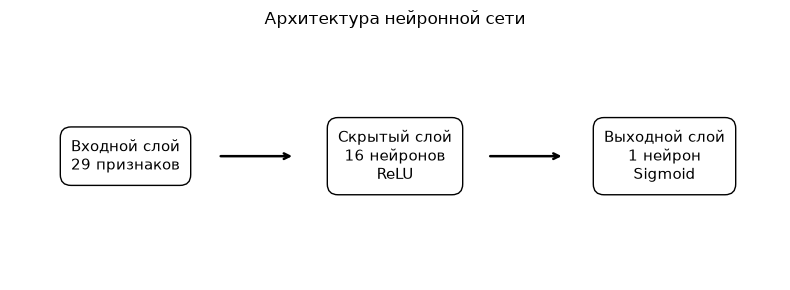

In [13]:
hidden_parameters = (num_features + 1) * 16
output_parameters = (16 + 1) * 1
print("Параметры скрытого слоя:", hidden_parameters)
print("Параметры выходного слоя:", output_parameters)
print("Всего параметров:", hidden_parameters + output_parameters)

# Схема архитектуры рисуется Matplotlib и не требует установки Graphviz.
fig, ax = plt.subplots(figsize=(8, 3))
ax.axis("off")
positions = [(0.15, 0.5), (0.50, 0.5), (0.85, 0.5)]
texts = [f"Входной слой\n{num_features} признаков", "Скрытый слой\n16 нейронов\nReLU", "Выходной слой\n1 нейрон\nSigmoid"]
for (x, y), label in zip(positions, texts):
    ax.text(x, y, label, ha="center", va="center", fontsize=11,
            bbox=dict(boxstyle="round,pad=0.7", fc="white", ec="black"))
ax.annotate("", xy=(0.37, 0.5), xytext=(0.27, 0.5),
            arrowprops=dict(arrowstyle="->", lw=1.8))
ax.annotate("", xy=(0.72, 0.5), xytext=(0.62, 0.5),
            arrowprops=dict(arrowstyle="->", lw=1.8))
ax.set_title("Архитектура нейронной сети")
plt.tight_layout()
plt.show()

## 5. Компиляция и обучение

- `adam` — оптимизатор, который изменяет веса сети для уменьшения ошибки;
- `binary_crossentropy` — функция потерь для бинарной классификации;
- `accuracy` — доля правильных ответов;
- `epochs=300` — максимум 300 проходов по обучающим данным;
- `batch_size=32` — размер мини-пакета;
- `validation_split=0.2` — 20% обучающей части используется для контроля качества во время обучения.

In [16]:
history = model.fit(
    X_train_np,
    y_train_np,
    epochs=300,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

## 6. Анализ процесса обучения

Графики сравнивают показатели на обучающей и валидационной частях. Если обучающая ошибка продолжает снижаться, а валидационная начинает расти, это может указывать на переобучение.

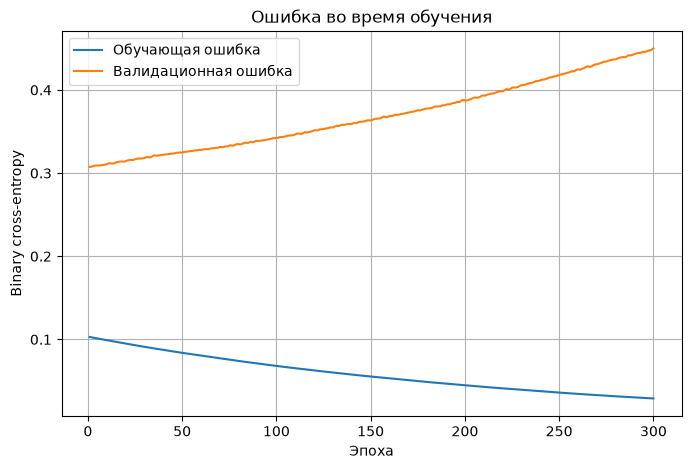

In [17]:
history_data = history.history
epochs = range(1, len(history_data["loss"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, history_data["loss"], label="Обучающая ошибка")
plt.plot(epochs, history_data["val_loss"], label="Валидационная ошибка")
plt.xlabel("Эпоха")
plt.ylabel("Binary cross-entropy")
plt.title("Ошибка во время обучения")
plt.legend()
plt.grid(True)
plt.show()

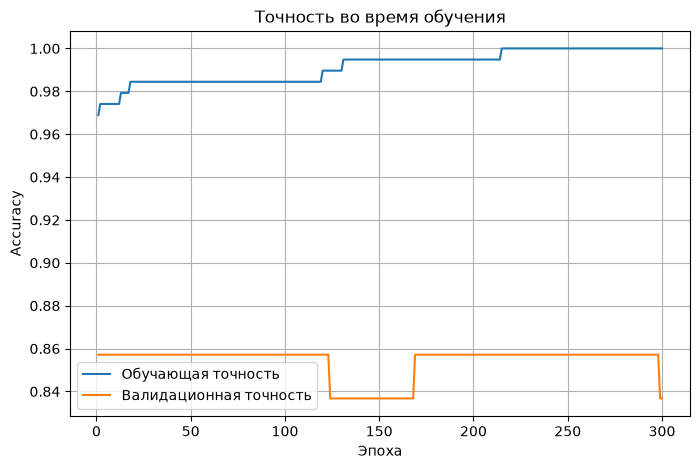

In [18]:
plt.figure(figsize=(8, 5))
plt.plot(epochs, history_data["accuracy"], label="Обучающая точность")
plt.plot(epochs, history_data["val_accuracy"], label="Валидационная точность")
plt.xlabel("Эпоха")
plt.ylabel("Accuracy")
plt.title("Точность во время обучения")
plt.legend()
plt.grid(True)
plt.show()

**Вопрос для анализа:** есть ли признаки переобучения? Сравните две кривые на каждом графике. Большой разрыв между обучающими и валидационными показателями, особенно при ухудшении валидационной ошибки, может указывать на переобучение. Конкретный вывод нужно сделать по графикам после запуска.

## 7. Итоговая оценка

Тестовая выборка не участвовала в обучении и используется только для финальной оценки. Сравним точность сети с точностью базовой модели.

In [21]:
test_loss, test_accuracy = model.evaluate(
    X_test_np,
    y_test_np,
    verbose=0
)

print(f"Потери на тестовой выборке: {test_loss:.4f}")
print(f"Точность на тестовой выборке: {test_accuracy:.1%}")
print(f"Точность базовой модели: {baseline_accuracy:.1%}")

Потери на тестовой выборке: 0.8836
Точность на тестовой выборке: 82.0%
Точность базовой модели: 72.6%


## 8. Прогноз для тестовых пациентов

Сигмоида возвращает вероятность класса 1. Порог `0.5` используется для превращения вероятности в бинарный прогноз. Эти прогнозы демонстрационные и не предназначены для медицинской диагностики.

In [24]:
probabilities = model.predict(X_test_np, verbose=0).ravel()
predictions = (probabilities >= 0.5).astype(int)

results = pd.DataFrame({
    "Фактический target": y_test_np.astype(int),
    "Вероятность target=1": probabilities,
    "Прогноз модели": predictions
})

display(results.head(10))

,Фактический target,Вероятность target=1,Прогноз модели
0,0,2.818708e-05,0
1,0,5.370041e-03,0
2,0,8.096001e-03,0
3,0,9.656836e-03,0
4,0,7.917417e-12,0
5,0,7.562101e-08,0
6,1,1.055956e-03,0
7,0,1.324971e-08,0
8,0,2.740827e-07,0
9,1,6.862011e-01,1


## 9. Визуальная оценка прогнозов

Матрица ошибок показывает, сколько объектов каждого класса модель определила верно и сколько перепутала. ROC-кривая показывает качество разделения классов при разных порогах.

In [25]:
# Матрица ошибок
cm = confusion_matrix(test_y.astype(int), predictions, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5.5, 4.5))
image = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1], labels=["Прогноз 0", "Прогноз 1"])
ax.set_yticks([0, 1], labels=["Факт 0", "Факт 1"])
ax.set_title("Матрица ошибок на тестовой выборке")
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=13)
fig.colorbar(image, ax=ax, label="Количество")
fig.tight_layout()
plt.show()

print("Отчёт по классам:")
print(classification_report(test_y.astype(int), predictions, labels=[0, 1],
                            target_names=["target = 0", "target = 1"], zero_division=0))


NameError: name 'test_y' is not defined

In [ ]:
# ROC-кривая и AUC: оцениваем вероятности, а не только готовые классы
if len(np.unique(test_y.astype(int))) == 2:
    fpr, tpr, thresholds = roc_curve(test_y.astype(int), probabilities)
    auc_value = roc_auc_score(test_y.astype(int), probabilities)
    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f"Нейронная сеть (AUC = {auc_value:.3f})")
    plt.plot([0, 1], [0, 1], linestyle="--", label="Случайный классификатор")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC-кривая на тестовой выборке")
    plt.legend(loc="lower right")
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()
    print(f"ROC-AUC: {auc_value:.3f}")
else:
    print("ROC-кривую нельзя построить: в тестовой выборке представлен только один класс.")


## Вывод

В работе выполнены загрузка и изучение табличных данных, кодирование категориальных признаков, стандартизация числовых признаков без использования статистик тестовой выборки, разделение данных, создание и обучение нейронной сети, анализ графиков и оценка качества на отложенной выборке. После запуска заполните вывод по фактической тестовой точности и графикам обучения.